Device: cuda


100%|██████████| 792M/792M [00:45<00:00, 17.3MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 7.96MB/s]


Training images: 2944
Validation images: 736
Testing images: 3669
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:05<00:00, 101MB/s]
Epoch 1: 100%|██████████| 92/92 [00:31<00:00,  2.93it/s]


Epoch 1: Train Loss=0.2171, Val Loss=0.0842


Epoch 2: 100%|██████████| 92/92 [00:29<00:00,  3.11it/s]


... (3 outputs left out)

Epoch 4: 100%|██████████| 92/92 [00:30<00:00,  3.02it/s]


Epoch 4: Train Loss=0.0402, Val Loss=0.0498


Epoch 5: 100%|██████████| 92/92 [00:31<00:00,  2.94it/s]


Epoch 5: Train Loss=0.0334, Val Loss=0.0292
Early Stopping
Test Accuracy: 98.9097846824748 %


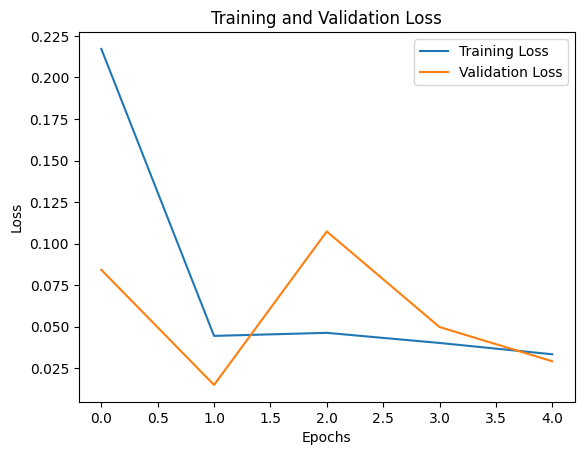

In [1]:

# 1. Import libraries
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
from copy import deepcopy
from tqdm import tqdm


# 2. Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 3. Image transformation
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# 4. Download dataset automatically
dataset = datasets.OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="binary-category",
    transform=transform,
    download=True
)

test_data = datasets.OxfordIIITPet(
    root="./data",
    split="test",
    target_types="binary-category",
    transform=transform,
    download=True
)

# 5. Split training and validation data
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_data, val_data = random_split(
    dataset, [train_size, val_size]
)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32)
test_loader = DataLoader(test_data, batch_size=32)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_data))

# 6. Load pretrained VGG16
model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)

# 7. Freeze convolutional layers
for param in model.features.parameters():
    param.requires_grad = False

# 8. Add custom classifier
model.classifier = nn.Sequential(
    nn.Linear(25088, 256),
    nn.ReLU(),
    nn.Dropout(0.7),
    nn.Linear(256, 2)
)

model = model.to(device)

# 9. Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=0.001)

# 10. Training
train_loss, val_loss = [], []

best_loss = float('inf')
best_weights = deepcopy(model.state_dict())
patience = 3
count = 0

for epoch in range(15):

    model.train()
    total_loss = 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}"):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    train_loss.append(total_loss / len(train_loader))

    # Validation
    model.eval()
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total += criterion(outputs, labels).item()

    v_loss = total / len(val_loader)
    val_loss.append(v_loss)

    print(f"Epoch {epoch+1}: Train Loss={train_loss[-1]:.4f}, Val Loss={v_loss:.4f}")

    # Early stopping
    if v_loss < best_loss:
        best_loss = v_loss
        best_weights = deepcopy(model.state_dict())
        count = 0
    else:
        count += 1

    if count == patience:
        print("Early Stopping")
        break

# 11. Restore best weights
model.load_state_dict(best_weights)

# 12. Calculate accuracy
model.eval()
correct, total = 0, 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print("Test Accuracy:", accuracy, "%")

# 13. Plot loss
plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()
